In [1]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns


## import data files 

In [4]:
df = 

SyntaxError: invalid syntax (1581804619.py, line 1)

In [5]:
def calculate_eular_score(df):

    patient_data = []
    
    for patient_id in df['record_id'].unique():
        patient_rows = df[df['record_id'] == patient_id]
        patient_info = patient_rows.iloc[0].copy()  # Get patient-level info
        
        # Calculate age at MRI
        if pd.notna(patient_info['dob']) and pd.notna(patient_info['mri_date']):
            try:
                # Handle different date formats
                if isinstance(patient_info['dob'], str):
                    dob = pd.to_datetime(patient_info['dob'])
                else:
                    dob = patient_info['dob']
                    
                if isinstance(patient_info['mri_date'], str):
                    mri_date = pd.to_datetime(patient_info['mri_date'])
                else:
                    mri_date = patient_info['mri_date']
                    
                age_at_mri = (mri_date - dob).days / 365.25
            except:
                age_at_mri = np.nan
        else:
            age_at_mri = np.nan
            
        # Get unique lesion locations for this patient
        lesion_locations = patient_rows['Lesion_location_region'].dropna().unique()
    
        patient_record = {
            'record_id': patient_id,
            'age_at_mri': age_at_mri,
            'known_diagnosis_wbmri': patient_info.get('known_diagnosis_wbmri'),
            'onset_of_symptoms': patient_info.get('onset_of_symptoms'),
            'diagnosis_date': patient_info.get('diagnosis_date'),
            'mri_date': patient_info.get('mri_date'),
            'bone_biopsy': patient_info.get('bone_biopsy'),
            'crp_result': patient_info.get('crp_result'),
            'sed_rate_result': patient_info.get('sed_rate_result'),
            'lesion_locations': lesion_locations,
            'total_lesions': len(patient_rows),
            # Add coexisting condition columns
            'prior_diagnoses_1___1': patient_info.get('prior_diagnoses_1___1'),
            'prior_diagnoses_1___2': patient_info.get('prior_diagnoses_1___2'), 
            'prior_diagnoses_1___3': patient_info.get('prior_diagnoses_1___3'),
            'prior_diagnoses_1___4': patient_info.get('prior_diagnoses_1___4'),
            'prior_diagnoses_other': patient_info.get('prior_diagnoses_other'),
            'associated_conditions___1': patient_info.get('associated_conditions___1'),
            'associated_conditions___2': patient_info.get('associated_conditions___2'),
            'associated_conditions___3': patient_info.get('associated_conditions___3'),
            'associated_conditions___4': patient_info.get('associated_conditions___4'),
            'associated_conditions___5': patient_info.get('associated_conditions___5'),
            'associated_conditions___6': patient_info.get('associated_conditions___6'),
            'associated_conditions___7': patient_info.get('associated_conditions___7'),
            'other': patient_info.get('other'),
            'has_biopsy_results': patient_id in biopsy_results
        }
        
        # Calculate months between diagnosis and MRI
        if pd.notna(patient_info.get('diagnosis_date')) and pd.notna(patient_info.get('mri_date')):
            try:
                diag_date = pd.to_datetime(patient_info['diagnosis_date'])
                mri_date = pd.to_datetime(patient_info['mri_date'])
                months_diff = (mri_date - diag_date).days / 30.44
                patient_record['months_between_diagnosis_and_mri'] = months_diff
            except:
                patient_record['months_between_diagnosis_and_mri'] = np.nan
        else:
            patient_record['months_between_diagnosis_and_mri'] = np.nan
            
        patient_data.append(patient_record)
    
    patient_df = pd.DataFrame(patient_data)
    
    # Calculate EULAR scores
    scores = []
    
    for _, patient in patient_df.iterrows():
        score = 0
        score_details = {}
        
        entry_criteria_met = True
        
        score_details['bone_pain_6wk'] = True
        
        if pd.notna(patient['age_at_mri']):
            age_at_onset = patient['age_at_mri'] < 18
            score_details['age_under_18'] = age_at_onset
            if not age_at_onset:
                entry_criteria_met = False
        else:
            score_details['age_under_18'] = None
            entry_criteria_met = False
            
        has_lesions = patient['total_lesions'] > 0
        score_details['abnormal_imaging'] = has_lesions
        if not has_lesions:
            entry_criteria_met = False
            
        score_details['entry_criteria_met'] = entry_criteria_met
        
        if not entry_criteria_met:
            scores.append({
                'record_id': patient['record_id'],
                'eular_score': 0,
                'classification': 'Does not meet entry criteria',
                'score_details': score_details
            })
            continue
            
        # Map biopsy result strings to their EULAR biopsy scores
        biopsy_score_lookup = {
            'inflammation and fibrosis': 17,
            'fibrosis and inflammation': 17,
            'fibrosis only': 11,
            'inflammation only': 9,
            'no inflammation or fibrosis': 0,
            'no fibrosis or inflammation': 0
        }
        # Bone biopsy results from dictionary
        biopsy_text = biopsy_results.get(str(patient['record_id']), '').lower()
        biopsy_score = biopsy_score_lookup.get(biopsy_text, 0)
        
        score += biopsy_score
        score_details['bone_biopsy_score'] = biopsy_score
        score_details['biopsy_text'] = biopsy_text  
        
        # Age at onset
        if pd.notna(patient['age_at_mri']) and patient['age_at_mri'] >= 3:
            score += 17
            score_details['age_score'] = 17
        else:
            score_details['age_score'] = 0
            
        # Sites of bone lesions
        lesion_sites = patient['lesion_locations']
        clavicle_involved = any('clavicle' in str(site).lower() for site in lesion_sites if pd.notna(site))
        mandible_involved = any('mandible' in str(site).lower() for site in lesion_sites if pd.notna(site))
        
        if clavicle_involved or mandible_involved:
            score += 16
            score_details['site_score'] = 16
        else:
            # Check for other specific sites
            other_sites = [site for site in lesion_sites if pd.notna(site) and 
                          'clavicle' not in str(site).lower() and 
                          'mandible' not in str(site).lower() and
                          'skull' not in str(site).lower() and
                          'hand' not in str(site).lower()]
            if len(other_sites) > 0:
                score += 9
                score_details['site_score'] = 9
            else:
                score_details['site_score'] = 0
                
        # Distribution pattern
        if patient['total_lesions'] >= 2:
            
            score += 9  # Assume multifocal lesions
            score_details['distribution_score'] = 9
        else:
            score_details['distribution_score'] = 0
            

        coexisting_score = 0
        coexisting_details = []
        
        has_ibd = False
        if pd.notna(patient.get('associated_conditions___3')) and patient['associated_conditions___3'] == 1:
            has_ibd = True
            coexisting_details.append('IBD (Crohns)')
        
        has_cutaneous = False
        cutaneous_conditions = []
        
        if pd.notna(patient.get('associated_conditions___1')) and patient['associated_conditions___1'] == 1:
            has_cutaneous = True
            cutaneous_conditions.append('Palmoplantar pustulosis')
            
        if pd.notna(patient.get('associated_conditions___2')) and patient['associated_conditions___2'] == 1:
            has_cutaneous = True
            cutaneous_conditions.append('Psoriasis')
        
        other_text = str(patient.get('other', '')).lower() if pd.notna(patient.get('other')) else ''
        prior_other_text = str(patient.get('prior_diagnoses_other', '')).lower() if pd.notna(patient.get('prior_diagnoses_other')) else ''
        
        cutaneous_keywords = ['pyoderma gangrenosum', 'acne fulminans', 'hidradenitis suppurativa', 
                             'pyoderma', 'acne', 'hidradenitis']
        
        for keyword in cutaneous_keywords:
            if keyword in other_text or keyword in prior_other_text:
                has_cutaneous = True
                cutaneous_conditions.append(f'Cutaneous condition ({keyword})')
                break
        
        # Check for axial arthritis
        has_axial_arthritis = False
        if pd.notna(patient.get('prior_diagnoses_1___2')) and patient['prior_diagnoses_1___2'] == 1:
            has_axial_arthritis = True  
            coexisting_details.append('Arthritis (assumed axial)')
        
        if pd.notna(patient.get('associated_conditions___4')) and patient['associated_conditions___4'] == 1:
            has_axial_arthritis = True
            coexisting_details.append('Arthritis (associated)')
        
        # Apply EULAR scoring hierarchy
        if has_ibd:
            coexisting_score = 9
            score_details['coexisting_condition'] = 'IBD'
        elif has_cutaneous:
            coexisting_score = 8
            score_details['coexisting_condition'] = f'Cutaneous: {", ".join(cutaneous_conditions)}'
        elif has_axial_arthritis:
            coexisting_score = 5
            score_details['coexisting_condition'] = 'Axial arthritis'
        else:
            coexisting_score = 0
            score_details['coexisting_condition'] = 'None'
        
        score += coexisting_score
        score_details['coexisting_score'] = coexisting_score
        score_details['coexisting_details'] = coexisting_details
        
        score_details['hemoglobin_score'] = 8
        score += 8
        
        score_details['fever_score'] = 0
        score += 8
        
        # ESR
        if pd.notna(patient['sed_rate_result']):
            try:
                esr_value = float(patient['sed_rate_result'])
                if esr_value >= 60:
                    score += 8
                    score_details['esr_score'] = 8
                else:
                    score_details['esr_score'] = 0
            except:
                score_details['esr_score'] = 0
        else:
            score_details['esr_score'] = 0
            
        # CRP
        if pd.notna(patient['crp_result']):
            try:
                crp_value = float(patient['crp_result'])
                if crp_value >= 30:
                    score += 8
                    score_details['crp_score'] = 8
                else:
                    score_details['crp_score'] = 0
            except:
                score_details['crp_score'] = 0
        else:
            score_details['crp_score'] = 0
            
        # Classification
        if score >= 55:
            classification = 'CNO'
        else:
            classification = 'Not CNO'
            
        scores.append({
            'record_id': patient['record_id'],
            'eular_score': score,
            'classification': classification,
            'score_details': score_details,
            'known_diagnosis': patient['known_diagnosis_wbmri'],
            'months_to_mri': patient['months_between_diagnosis_and_mri']
        })
    
    return pd.DataFrame(scores), patient_df

def analyze_eular_performance(scores_df):
    """
    Analyze how well EULAR criteria perform in this cohort
    """
    print("EULAR CNO Classification Analysis")
    print("=" * 50)
    
    # Overall classification results
    print(f"Total patients analyzed: {len(scores_df)}")
    print(f"Patients meeting entry criteria: {sum(scores_df['classification'] != 'Does not meet entry criteria')}")
    print(f"Patients classified as CNO: {sum(scores_df['classification'] == 'CNO')}")
    print(f"Patients classified as Not CNO: {sum(scores_df['classification'] == 'Not CNO')}")
    
    # Score distribution
    valid_scores = scores_df[scores_df['classification'] != 'Does not meet entry criteria']['eular_score']
    print(f"\nScore distribution (valid patients):")
    print(f"Mean score: {valid_scores.mean():.1f}")
    print(f"Median score: {valid_scores.median():.1f}")
    print(f"Range: {valid_scores.min()}-{valid_scores.max()}")
    
    # Compare with known diagnosis
    if 'known_diagnosis' in scores_df.columns:
        known_cno = scores_df[scores_df['known_diagnosis'] == 1]
        unknown_cno = scores_df[scores_df['known_diagnosis'] != 1]
        
        print(f"\nComparison with known CNO diagnosis:")
        if len(known_cno) > 0:
            print(f"Patients with known CNO diagnosis: {len(known_cno)}")
            print(f"  - Classified as CNO by EULAR: {sum(known_cno['classification'] == 'CNO')}")
            print(f"  - Mean EULAR score: {known_cno['eular_score'].mean():.1f}")
            
        if len(unknown_cno) > 0:
            print(f"Patients without known CNO diagnosis: {len(unknown_cno)}")
            print(f"  - Classified as CNO by EULAR: {sum(unknown_cno['classification'] == 'CNO')}")
            print(f"  - Mean EULAR score: {unknown_cno['eular_score'].mean():.1f}")
    
    # Coexisting conditions analysis
    print(f"\nCoexisting conditions analysis:")
    valid_patients = scores_df[scores_df['classification'] != 'Does not meet entry criteria']
    
    coexisting_counts = {}
    for _, row in valid_patients.iterrows():
        condition = row['score_details'].get('coexisting_condition', 'None')
        coexisting_counts[condition] = coexisting_counts.get(condition, 0) + 1
    
    print("Coexisting condition distribution:")
    for condition, count in sorted(coexisting_counts.items(), key=lambda x: x[1], reverse=True):
        print(f"  - {condition}: {count} patients")
    
    # Time-based analysis
    if 'months_to_mri' in scores_df.columns:
        valid_time = scores_df.dropna(subset=['months_to_mri'])
        if len(valid_time) > 0:
            print(f"\nTime between diagnosis and MRI analysis:")
            early_mri = valid_time[valid_time['months_to_mri'] <= 6]
            late_mri = valid_time[valid_time['months_to_mri'] > 6]
            
            if len(early_mri) > 0:
                print(f"Early MRI (≤6 months): {len(early_mri)} patients")
                print(f"  - Mean EULAR score: {early_mri['eular_score'].mean():.1f}")
                print(f"  - CNO classification rate: {sum(early_mri['classification'] == 'CNO')/len(early_mri)*100:.1f}%")
                
            if len(late_mri) > 0:
                print(f"Late MRI (>6 months): {len(late_mri)} patients")
                print(f"  - Mean EULAR score: {late_mri['eular_score'].mean():.1f}")
                print(f"  - CNO classification rate: {sum(late_mri['classification'] == 'CNO')/len(late_mri)*100:.1f}%")
    
    return scores_df

def create_eular_visualizations(scores_df):
    """
    Create visualizations of EULAR score analysis
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # Score distribution
    valid_scores = scores_df[scores_df['classification'] != 'Does not meet entry criteria']
    axes[0,0].hist(valid_scores['eular_score'], bins=20, edgecolor='black', alpha=0.7)
    axes[0,0].axvline(x=55, color='red', linestyle='--', label='CNO Threshold (55)')
    axes[0,0].set_xlabel('EULAR Score')
    axes[0,0].set_ylabel('Number of Patients')
    axes[0,0].set_title('Distribution of EULAR Scores')
    axes[0,0].legend()
    
    # Classification results
    class_counts = scores_df['classification'].value_counts()
    axes[0,1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%')
    axes[0,1].set_title('EULAR Classification Results')
    
    # Known diagnosis vs EULAR classification
    if 'known_diagnosis' in scores_df.columns:
        crosstab = pd.crosstab(scores_df['known_diagnosis'].fillna('Unknown'), 
                              scores_df['classification'])
        crosstab.plot(kind='bar', ax=axes[1,0])
        axes[1,0].set_xlabel('Known CNO Diagnosis')
        axes[1,0].set_ylabel('Count')
        axes[1,0].set_title('Known Diagnosis vs EULAR Classification')
        axes[1,0].tick_params(axis='x', rotation=45)
    
    # Score by time to MRI
    if 'months_to_mri' in scores_df.columns:
        valid_time = scores_df.dropna(subset=['months_to_mri', 'eular_score'])
        if len(valid_time) > 0:
            axes[1,1].scatter(valid_time['months_to_mri'], valid_time['eular_score'], 
                             alpha=0.6)
            axes[1,1].axhline(y=55, color='red', linestyle='--', label='CNO Threshold')
            axes[1,1].set_xlabel('Months between Diagnosis and MRI')
            axes[1,1].set_ylabel('EULAR Score')
            axes[1,1].set_title('EULAR Score vs Time to MRI')
            axes[1,1].legend()
    
    plt.tight_layout()
    plt.show()
    
    return fig


scores_df, patient_df = calculate_eular_score(combined)
analyze_eular_performance(scores_df)
create_eular_visualizations(scores_df)

NameError: name 'combined' is not defined

In [2]:
def calculate_eular_score(df):
    """
    Calculate EULAR CNO classification scores for patients
    """
    # Create patient-level dataset by aggregating lesion data
    patient_data = []
    
    for patient_id in df['record_id'].unique():
        patient_rows = df[df['record_id'] == patient_id]
        patient_info = patient_rows.iloc[0].copy()  # Get patient-level info
        
        # Calculate age at MRI
        if pd.notna(patient_info['dob']) and pd.notna(patient_info['mri_date']):
            try:
                # Handle different date formats
                if isinstance(patient_info['dob'], str):
                    dob = pd.to_datetime(patient_info['dob'])
                else:
                    dob = patient_info['dob']
                    
                if isinstance(patient_info['mri_date'], str):
                    mri_date = pd.to_datetime(patient_info['mri_date'])
                else:
                    mri_date = patient_info['mri_date']
                    
                age_at_mri = (mri_date - dob).days / 365.25
            except:
                age_at_mri = np.nan
        else:
            age_at_mri = np.nan
            
        # Get unique lesion locations for this patient
        lesion_locations = patient_rows['Lesion_location_region'].dropna().unique()
    
        patient_record = {
            'record_id': patient_id,
            'age_at_mri': age_at_mri,
            'known_diagnosis_wbmri': patient_info.get('known_diagnosis_wbmri'),
            'onset_of_symptoms': patient_info.get('onset_of_symptoms'),
            'diagnosis_date': patient_info.get('diagnosis_date'),
            'mri_date': patient_info.get('mri_date'),
            'bone_biopsy': patient_info.get('bone_biopsy'),
            'crp_result': patient_info.get('crp_result'),
            'sed_rate_result': patient_info.get('sed_rate_result'),
            'lesion_locations': lesion_locations,
            'total_lesions': len(patient_rows),
            # Add coexisting condition columns
            'prior_diagnoses_1___1': patient_info.get('prior_diagnoses_1___1'),
            'prior_diagnoses_1___2': patient_info.get('prior_diagnoses_1___2'), 
            'prior_diagnoses_1___3': patient_info.get('prior_diagnoses_1___3'),
            'prior_diagnoses_1___4': patient_info.get('prior_diagnoses_1___4'),
            'prior_diagnoses_other': patient_info.get('prior_diagnoses_other'),
            'associated_conditions___1': patient_info.get('associated_conditions___1'),
            'associated_conditions___2': patient_info.get('associated_conditions___2'),
            'associated_conditions___3': patient_info.get('associated_conditions___3'),
            'associated_conditions___4': patient_info.get('associated_conditions___4'),
            'associated_conditions___5': patient_info.get('associated_conditions___5'),
            'associated_conditions___6': patient_info.get('associated_conditions___6'),
            'associated_conditions___7': patient_info.get('associated_conditions___7'),
            'other': patient_info.get('other'),
            'has_biopsy_results': patient_id in biopsy_results
        }
        
        # Calculate months between diagnosis and MRI
        if pd.notna(patient_info.get('diagnosis_date')) and pd.notna(patient_info.get('mri_date')):
            try:
                diag_date = pd.to_datetime(patient_info['diagnosis_date'])
                mri_date = pd.to_datetime(patient_info['mri_date'])
                months_diff = (mri_date - diag_date).days / 30.44
                patient_record['months_between_diagnosis_and_mri'] = months_diff
            except:
                patient_record['months_between_diagnosis_and_mri'] = np.nan
        else:
            patient_record['months_between_diagnosis_and_mri'] = np.nan
            
        patient_data.append(patient_record)
    
    patient_df = pd.DataFrame(patient_data)
    
    # Calculate EULAR scores
    scores = []
    
    for _, patient in patient_df.iterrows():
        score = 0
        score_details = {}
        
        # Step 1: Entry criteria (must have all)
        entry_criteria_met = True
        
        # 1. Bone pain/functional limitation ≥6 weeks (assume met if they're in study)
        score_details['bone_pain_6wk'] = True
        
        # 2. Age <18y at onset
        if pd.notna(patient['age_at_mri']):
            age_at_onset = patient['age_at_mri'] < 18
            score_details['age_under_18'] = age_at_onset
            if not age_at_onset:
                entry_criteria_met = False
        else:
            score_details['age_under_18'] = None
            entry_criteria_met = False
            
        # 3. Abnormal imaging findings (assume met if lesions present)
        has_lesions = patient['total_lesions'] > 0
        score_details['abnormal_imaging'] = has_lesions
        if not has_lesions:
            entry_criteria_met = False
            
        score_details['entry_criteria_met'] = entry_criteria_met
        
        if not entry_criteria_met:
            scores.append({
                'record_id': patient['record_id'],
                'eular_score': 0,
                'classification': 'Does not meet entry criteria',
                'score_details': score_details
            })
            continue
          
        # Step 3: Scoring criteria
        # Map biopsy result strings to their EULAR biopsy scores
        biopsy_score_lookup = {
            'inflammation and fibrosis': 17,
            'fibrosis and inflammation': 17,
            'fibrosis only': 11,
            'inflammation only': 9,
            'no inflammation or fibrosis': 0,
            'no fibrosis or inflammation': 0
        }
        # Bone biopsy results from dictionary
        biopsy_text = biopsy_results.get(str(patient['record_id']), '').lower()
        biopsy_score = biopsy_score_lookup.get(biopsy_text, 0)
        
        score += biopsy_score
        score_details['bone_biopsy_score'] = biopsy_score
        score_details['biopsy_text'] = biopsy_text 

        # Age at onset
        if pd.notna(patient['age_at_mri']) and patient['age_at_mri'] >= 3:
            score += 17
            score_details['age_score'] = 17
        else:
            score_details['age_score'] = 0
            
        # Sites of bone lesions
        lesion_sites = patient['lesion_locations']
        clavicle_involved = any('clavicle' in str(site).lower() for site in lesion_sites if pd.notna(site))
        mandible_involved = any('mandible' in str(site).lower() for site in lesion_sites if pd.notna(site))
        
        if clavicle_involved or mandible_involved:
            score += 16
            score_details['site_score'] = 16
        else:
            # Check for other specific sites
            other_sites = [site for site in lesion_sites if pd.notna(site) and 
                          'clavicle' not in str(site).lower() and 
                          'mandible' not in str(site).lower() and
                          'skull' not in str(site).lower() and
                          'hand' not in str(site).lower()]
            if len(other_sites) > 0:
                score += 9
                score_details['site_score'] = 9
            else:
                score_details['site_score'] = 0
                
        # Distribution pattern
        if patient['total_lesions'] >= 2:
            score += 9  
            score_details['distribution_score'] = 9
        else:
            score_details['distribution_score'] = 0
            
        coexisting_score = 0
        coexisting_details = []
        
        # Check for IBD (Crohn's disease in associated conditions)
        has_ibd = False
        if pd.notna(patient.get('associated_conditions___3')) and patient['associated_conditions___3'] == 1:
            has_ibd = True
            coexisting_details.append('IBD (Crohns)')
        
        # Check for cutaneous conditions
        has_cutaneous = False
        cutaneous_conditions = []
        
        # Check associated conditions checkboxes
        if pd.notna(patient.get('associated_conditions___1')) and patient['associated_conditions___1'] == 1:
            has_cutaneous = True
            cutaneous_conditions.append('Palmoplantar pustulosis')
            
        if pd.notna(patient.get('associated_conditions___2')) and patient['associated_conditions___2'] == 1:
            has_cutaneous = True
            cutaneous_conditions.append('Psoriasis')
        
        # Check free text fields for additional cutaneous conditions
        other_text = str(patient.get('other', '')).lower() if pd.notna(patient.get('other')) else ''
        prior_other_text = str(patient.get('prior_diagnoses_other', '')).lower() if pd.notna(patient.get('prior_diagnoses_other')) else ''
        
        cutaneous_keywords = ['pyoderma gangrenosum', 'acne fulminans', 'hidradenitis suppurativa', 
                             'pyoderma', 'acne', 'hidradenitis']
        
        for keyword in cutaneous_keywords:
            if keyword in other_text or keyword in prior_other_text:
                has_cutaneous = True
                cutaneous_conditions.append(f'Cutaneous condition ({keyword})')
                break
        
        # Check for axial arthritis
        has_axial_arthritis = False
        if pd.notna(patient.get('prior_diagnoses_1___2')) and patient['prior_diagnoses_1___2'] == 1:
            has_axial_arthritis = True  
            coexisting_details.append('Arthritis (assumed axial)')
        
        if pd.notna(patient.get('associated_conditions___4')) and patient['associated_conditions___4'] == 1:
            has_axial_arthritis = True
            coexisting_details.append('Arthritis (associated)')
        
        # Apply EULAR scoring hierarchy
        if has_ibd:
            coexisting_score = 9
            score_details['coexisting_condition'] = 'IBD'
        elif has_cutaneous:
            coexisting_score = 8
            score_details['coexisting_condition'] = f'Cutaneous: {", ".join(cutaneous_conditions)}'
        elif has_axial_arthritis:
            coexisting_score = 5
            score_details['coexisting_condition'] = 'Axial arthritis'
        else:
            coexisting_score = 0
            score_details['coexisting_condition'] = 'None'
        
        score += coexisting_score
        score_details['coexisting_score'] = coexisting_score
        score_details['coexisting_details'] = coexisting_details
        
        score_details['hemoglobin_score'] = 8
        score += 8
        
        score_details['fever_score'] = 0
        score += 8
        
        # ESR
        if pd.notna(patient['sed_rate_result']):
            try:
                esr_value = float(patient['sed_rate_result'])
                if esr_value >= 60:
                    score += 8
                    score_details['esr_score'] = 8
                else:
                    score_details['esr_score'] = 0
            except:
                score_details['esr_score'] = 0
        else:
            score_details['esr_score'] = 0
            
        # CRP
        if pd.notna(patient['crp_result']):
            try:
                crp_value = float(patient['crp_result'])
                if crp_value >= 30:
                    score += 8
                    score_details['crp_score'] = 8
                else:
                    score_details['crp_score'] = 0
            except:
                score_details['crp_score'] = 0
        else:
            score_details['crp_score'] = 0
            
        # Classification
        if score >= 55:
            classification = 'CNO'
        else:
            classification = 'Not CNO'
            
        scores.append({
            'record_id': patient['record_id'],
            'eular_score': score,
            'classification': classification,
            'score_details': score_details,
            'known_diagnosis': patient['known_diagnosis_wbmri'],
            'months_to_mri': patient['months_between_diagnosis_and_mri']
        })
    
    return pd.DataFrame(scores), patient_df

def analyze_eular_performance(scores_df):

    print("EULAR CNO Classification Analysis")
    print("=" * 50)
    
    # Overall classification results
    print(f"Total patients analyzed: {len(scores_df)}")
    print(f"Patients meeting entry criteria: {sum(scores_df['classification'] != 'Does not meet entry criteria')}")
    print(f"Patients classified as CNO: {sum(scores_df['classification'] == 'CNO')}")
    print(f"Patients classified as Not CNO: {sum(scores_df['classification'] == 'Not CNO')}")
    
    # Score distribution
    valid_scores = scores_df[scores_df['classification'] != 'Does not meet entry criteria']['eular_score']
    print(f"\nScore distribution (valid patients):")
    print(f"Mean score: {valid_scores.mean():.1f}")
    print(f"Median score: {valid_scores.median():.1f}")
    print(f"Range: {valid_scores.min()}-{valid_scores.max()}")
    
    # Compare with known diagnosis
    if 'known_diagnosis' in scores_df.columns:
        known_cno = scores_df[scores_df['known_diagnosis'] == 1]
        unknown_cno = scores_df[scores_df['known_diagnosis'] != 1]
        
        print(f"\nComparison with known CNO diagnosis:")
        if len(known_cno) > 0:
            print(f"Patients with known CNO diagnosis: {len(known_cno)}")
            print(f"  - Classified as CNO by EULAR: {sum(known_cno['classification'] == 'CNO')}")
            print(f"  - Mean EULAR score: {known_cno['eular_score'].mean():.1f}")
            
        if len(unknown_cno) > 0:
            print(f"Patients without known CNO diagnosis: {len(unknown_cno)}")
            print(f"  - Classified as CNO by EULAR: {sum(unknown_cno['classification'] == 'CNO')}")
            print(f"  - Mean EULAR score: {unknown_cno['eular_score'].mean():.1f}")
    
    # Coexisting conditions analysis
    print(f"\nCoexisting conditions analysis:")
    valid_patients = scores_df[scores_df['classification'] != 'Does not meet entry criteria']
    
    coexisting_counts = {}
    for _, row in valid_patients.iterrows():
        condition = row['score_details'].get('coexisting_condition', 'None')
        coexisting_counts[condition] = coexisting_counts.get(condition, 0) + 1
    
    print("Coexisting condition distribution:")
    for condition, count in sorted(coexisting_counts.items(), key=lambda x: x[1], reverse=True):
        print(f"  - {condition}: {count} patients")
    
    # Time-based analysis
    if 'months_to_mri' in scores_df.columns:
        valid_time = scores_df.dropna(subset=['months_to_mri'])
        if len(valid_time) > 0:
            print(f"\nTime between diagnosis and MRI analysis:")
            early_mri = valid_time[valid_time['months_to_mri'] <= 6]
            late_mri = valid_time[valid_time['months_to_mri'] > 6]
            
            if len(early_mri) > 0:
                print(f"Early MRI (≤6 months): {len(early_mri)} patients")
                print(f"  - Mean EULAR score: {early_mri['eular_score'].mean():.1f}")
                print(f"  - CNO classification rate: {sum(early_mri['classification'] == 'CNO')/len(early_mri)*100:.1f}%")
                
            if len(late_mri) > 0:
                print(f"Late MRI (>6 months): {len(late_mri)} patients")
                print(f"  - Mean EULAR score: {late_mri['eular_score'].mean():.1f}")
                print(f"  - CNO classification rate: {sum(late_mri['classification'] == 'CNO')/len(late_mri)*100:.1f}%")
    
    return scores_df

def create_eular_visualizations(scores_df):
    """
    Create visualizations of EULAR score analysis
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # Score distribution
    valid_scores = scores_df[scores_df['classification'] != 'Does not meet entry criteria']
    axes[0,0].hist(valid_scores['eular_score'], bins=20, edgecolor='black', alpha=0.7)
    axes[0,0].axvline(x=55, color='red', linestyle='--', label='CNO Threshold (55)')
    axes[0,0].set_xlabel('EULAR Score')
    axes[0,0].set_ylabel('Number of Patients')
    axes[0,0].set_title('Distribution of EULAR Scores')
    axes[0,0].legend()
    
    # Classification results
    class_counts = scores_df['classification'].value_counts()
    axes[0,1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%')
    axes[0,1].set_title('EULAR Classification Results')
    
    # Known diagnosis vs EULAR classification
    if 'known_diagnosis' in scores_df.columns:
        crosstab = pd.crosstab(scores_df['known_diagnosis'].fillna('Unknown'), 
                              scores_df['classification'])
        crosstab.plot(kind='bar', ax=axes[1,0])
        axes[1,0].set_xlabel('Known CNO Diagnosis')
        axes[1,0].set_ylabel('Count')
        axes[1,0].set_title('Known Diagnosis vs EULAR Classification')
        axes[1,0].tick_params(axis='x', rotation=45)
    
    # Score by time to MRI
    if 'months_to_mri' in scores_df.columns:
        valid_time = scores_df.dropna(subset=['months_to_mri', 'eular_score'])
        if len(valid_time) > 0:
            axes[1,1].scatter(valid_time['months_to_mri'], valid_time['eular_score'], 
                             alpha=0.6)
            axes[1,1].axhline(y=55, color='red', linestyle='--', label='CNO Threshold')
            axes[1,1].set_xlabel('Months between Diagnosis and MRI')
            axes[1,1].set_ylabel('EULAR Score')
            axes[1,1].set_title('EULAR Score vs Time to MRI')
            axes[1,1].legend()
    
    plt.tight_layout()
    plt.show()
    
    return fig

# Example usage:
print("EULAR CNO Classification Code with Fixed Coexisting Conditions Ready!")
print("\nTo use this code:")
print("1. Load your data into a DataFrame called 'df'")
print("2. Run: scores_df, patient_df = calculate_eular_score(df)")
print("3. Run: analyze_eular_performance(scores_df)")
print("4. Run: create_eular_visualizations(scores_df)")
print("\nThe code will:")
print("- Calculate EULAR scores for each patient")
print("- Properly handle coexisting conditions based on your data structure")
print("- Compare classifications with known diagnoses")
print("- Analyze performance by time between diagnosis and MRI")
print("- Create visualizations of the results")

scores_df, patient_df = calculate_eular_score(combined)
analyze_eular_performance(scores_df)
create_eular_visualizations(scores_df)

NameError: name 'combined' is not defined

# stats for specificity and sensitivity 

In [3]:
from statsmodels.stats.proportion import proportion_confint

def test_eular_performance_vs_chance(scores_df):
    """
    Reports sensitivity and specificity of EULAR classification vs known diagnosis,
    with 95% confidence intervals
    """
    # Known CNO patients (sensitivity)
    known_cno = scores_df[scores_df['known_diagnosis'] == 1]
    if len(known_cno) > 0:
        successes_cno = sum(known_cno['classification'] == 'CNO')
        n_cno = len(known_cno)
        sensitivity = successes_cno / n_cno
        ci_low, ci_upp = proportion_confint(count=successes_cno, nobs=n_cno, alpha=0.05, method='wilson')
        print(f"Sensitivity (CNO patients): {sensitivity:.2%} ({successes_cno}/{n_cno})")
        print(f"95% CI: {ci_low:.2%} to {ci_upp:.2%}")
    else:
        print("No known CNO patients available for testing.")
    
    print("\n" + "-"*50 + "\n")
    
    # Known Not CNO patients (specificity)
    known_not_cno = scores_df[scores_df['known_diagnosis'] == 0]
    if len(known_not_cno) > 0:
        successes_not_cno = sum(known_not_cno['classification'] == 'Not CNO')
        n_not_cno = len(known_not_cno)
        specificity = successes_not_cno / n_not_cno
        ci_low, ci_upp = proportion_confint(count=successes_not_cno, nobs=n_not_cno, alpha=0.05, method='wilson')
        print(f"Specificity (Not CNO patients): {specificity:.2%} ({successes_not_cno}/{n_not_cno})")
        print(f"95% CI: {ci_low:.2%} to {ci_upp:.2%}")
    else:
        print("No known Not CNO patients available for testing.")

# Usage:
test_eular_performance_vs_chance(scores_df)


NameError: name 'scores_df' is not defined

# manuscript figures

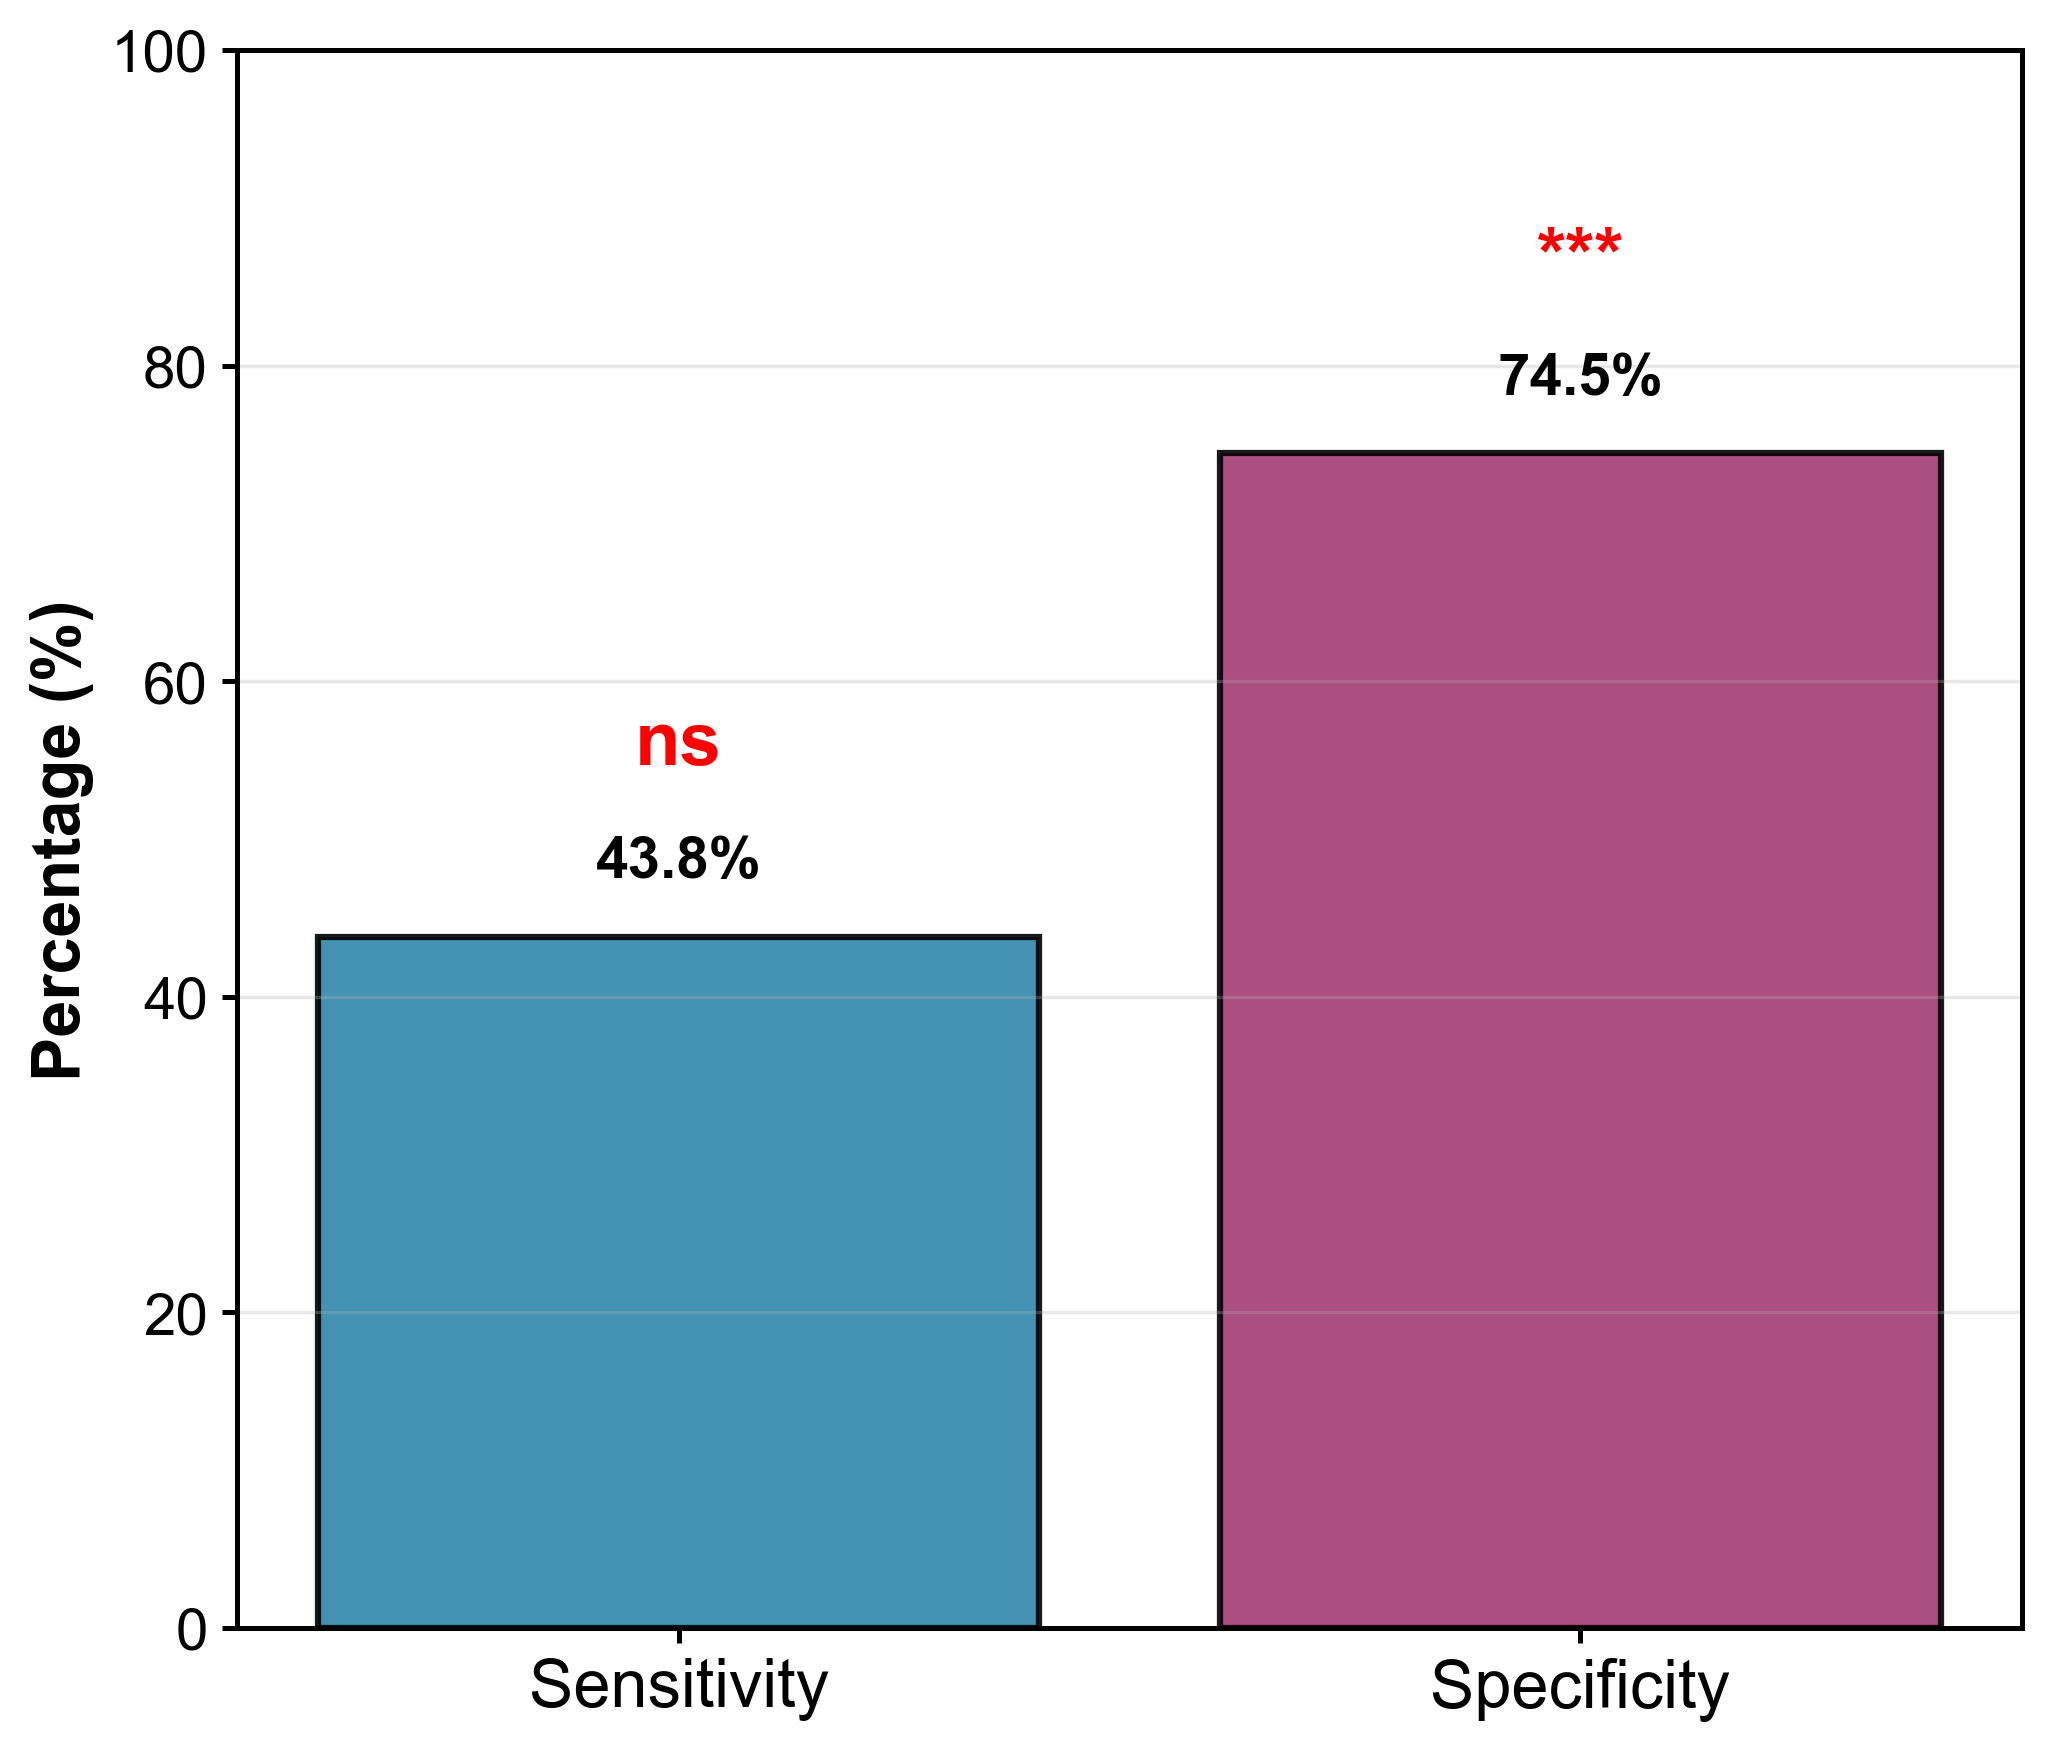

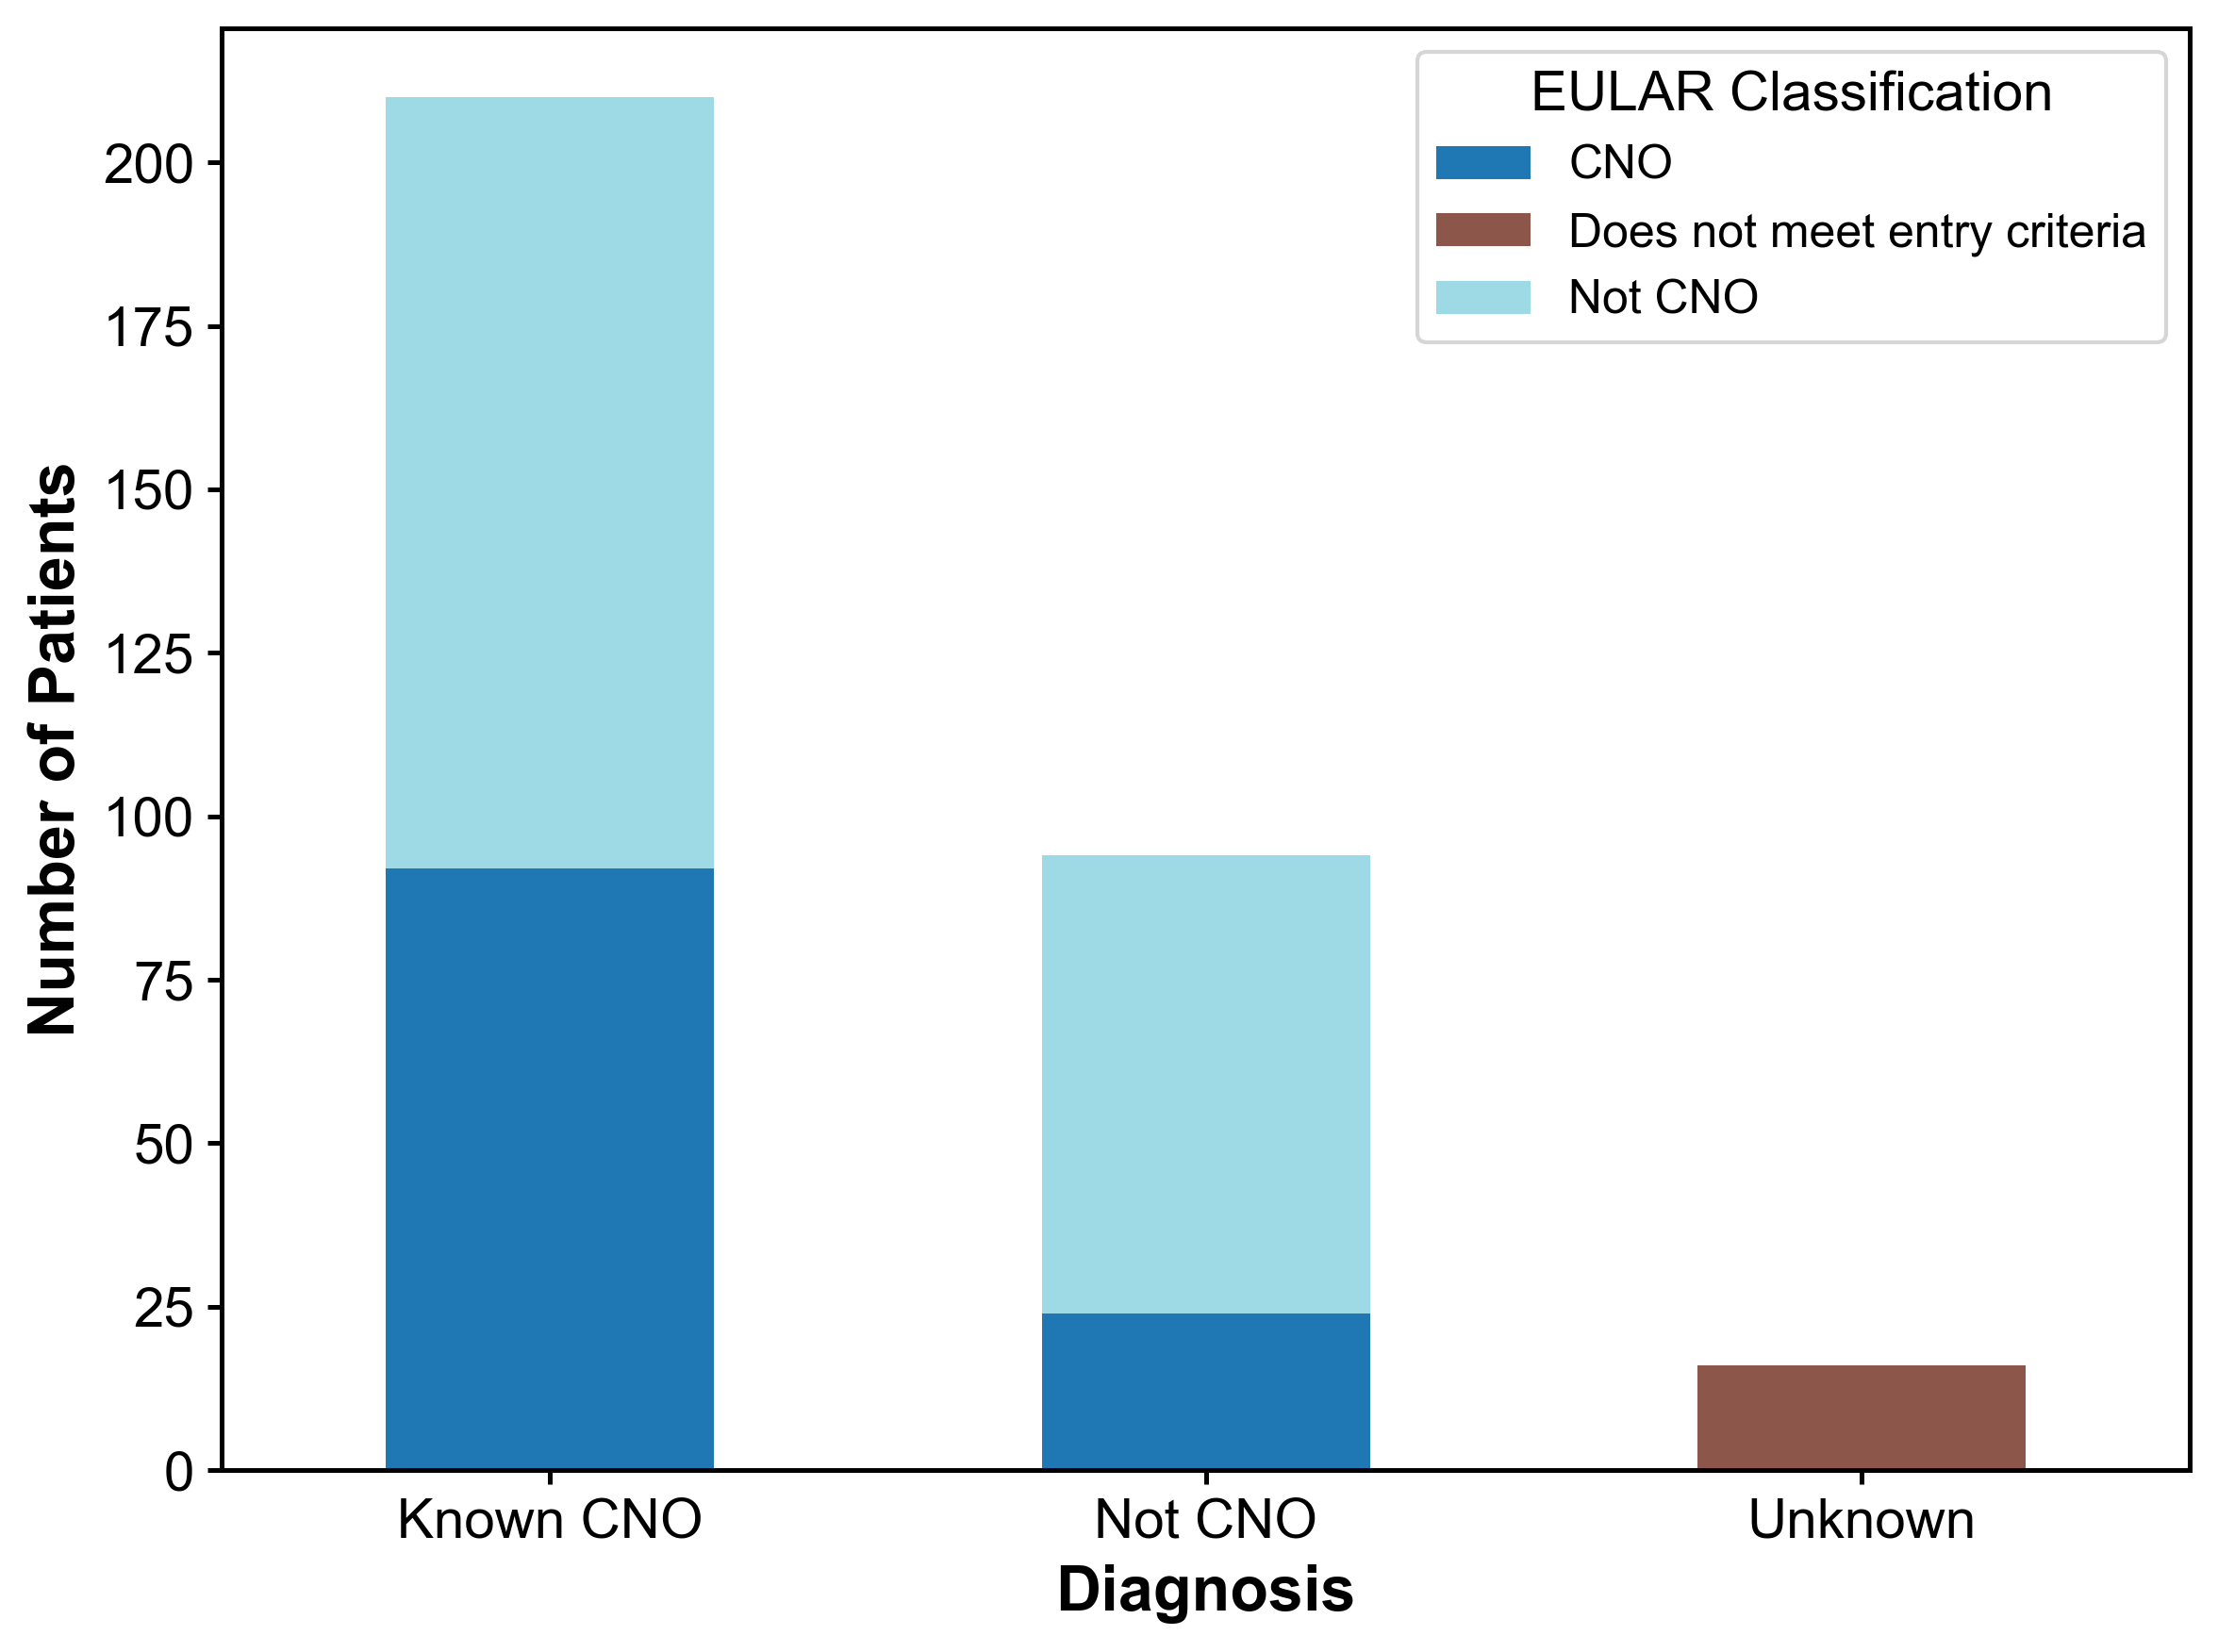

In [38]:
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

def plot_sensitivity_specificity(scores_df):
    """
    Create a sensitivity and specificity bar plot with stats for manuscript.
    """
    colors = {'CNO': '#2E86AB', 'Not CNO': '#A23B72'}

    valid_patients = scores_df[scores_df['classification'] != 'Does not meet entry criteria']
    known_cno = valid_patients[valid_patients['known_diagnosis'] == 1]
    known_not_cno = valid_patients[valid_patients['known_diagnosis'] == 0]

    # Calculate sensitivity and specificity in %
    sensitivity = sum(known_cno['classification'] == 'CNO') / len(known_cno) * 100
    specificity = sum(known_not_cno['classification'] == 'Not CNO') / len(known_not_cno) * 100

    # Proportion tests against 50%
    sens_success = sum(known_cno['classification'] == 'CNO')
    spec_success = sum(known_not_cno['classification'] == 'Not CNO')
    
    sens_stat, sens_pval = proportions_ztest(count=sens_success, nobs=len(known_cno), value=0.5, alternative='larger')
    spec_stat, spec_pval = proportions_ztest(count=spec_success, nobs=len(known_not_cno), value=0.5, alternative='larger')

    # Create figure
    fig, ax = plt.subplots(figsize=(7, 6))
    metrics = ['Sensitivity', 'Specificity']
    values = [sensitivity, specificity]
    colors_metrics = [colors['CNO'], colors['Not CNO']]

    bars = ax.bar(metrics, values, color=colors_metrics, alpha=0.9, edgecolor='black', linewidth=1.5)
    ax.set_ylim(0, 100)
    ax.set_ylabel('Percentage (%)', fontsize=16, fontweight='bold')
    #ax.set_title('EULAR Criteria Performance vs Known Diagnosis', fontsize=20, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=14)

    # Add value labels and significance stars
    for i, (bar, value) in enumerate(zip(bars, values)):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3, f'{value:.1f}%', 
                ha='center', va='bottom', fontweight='bold', fontsize=14)
        
        pval = sens_pval if i == 0 else spec_pval
        sig = ''
        if pval < 0.001:
            sig = '***'
        elif pval < 0.01:
            sig = '**'
        elif pval < 0.05:
            sig = '*'
        else:
            sig = 'ns'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, sig, 
                ha='center', va='bottom', fontsize=18, color='red', fontweight='bold')

    plt.tight_layout()
    return fig


def plot_known_vs_eular_stacked(scores_df):
    """
    Create a stacked bar plot of Known Diagnosis vs EULAR Classification for manuscript.
    """
    if 'known_diagnosis' not in scores_df.columns:
        raise ValueError("Input dataframe must contain 'known_diagnosis' column.")

    df_plot = scores_df.copy()
    df_plot['known_diagnosis_label'] = df_plot['known_diagnosis'].map({1: 'Known CNO', 0: 'Not CNO'}).fillna('Unknown')

    crosstab = pd.crosstab(df_plot['known_diagnosis_label'], df_plot['classification'])

    fig, ax = plt.subplots(figsize=(8, 6))
    crosstab.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')

    ax.set_xlabel('Diagnosis', fontsize=16, fontweight='bold')
    ax.set_ylabel('Number of Patients', fontsize=16, fontweight='bold')
    #ax.set_title('EULAR Classification vs Known Diagnosis', fontsize=20, fontweight='bold')

    ax.legend(title='EULAR Classification', fontsize=12, title_fontsize=14)
    ax.tick_params(axis='x', rotation=0, labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    plt.tight_layout()
    return fig

# Sensitivity & Specificity plot
fig1 = plot_sensitivity_specificity(scores_df)
fig1.savefig('sensitivity_specificity_poster.png', dpi=300)

# Stacked bar plot
fig2 = plot_known_vs_eular_stacked(scores_df)
fig2.savefig('stacked_known_vs_eular_poster.png', dpi=300)
